In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import lightgbm as lgb

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE = 42

print("Импорты загружены")

Импорты загружены


In [2]:
wine_path = kagglehub.dataset_download("yasserh/wine-quality-dataset")
wine_file = [f for f in os.listdir(wine_path) if f.endswith('.csv')][0]
wine = pd.read_csv(os.path.join(wine_path, wine_file))

print(f"Wine размерность: {wine.shape}")
print(f"Классы: {sorted(wine['quality'].unique())}")

Wine размерность: (1143, 13)
Классы: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [3]:
churn_path = kagglehub.dataset_download("blastchar/telco-customer-churn")
churn_file = [f for f in os.listdir(churn_path) if f.endswith('.csv')][0]
churn = pd.read_csv(os.path.join(churn_path, churn_file))

print(f"Churn размерность: {churn.shape}")
print(f"Распределение Churn: {churn['Churn'].value_counts().to_dict()}")

Churn размерность: (7043, 21)
Распределение Churn: {'No': 5174, 'Yes': 1869}


In [4]:
X_wine = wine.drop(columns=['quality', 'Id'])
y_wine = wine['quality']

# XGBoost и LightGBM требуют классы 0..N-1
# Перекодируем 3,4,5,6,7,8 → 0,1,2,3,4,5
label_encoder_wine = LabelEncoder()
y_wine_encoded = label_encoder_wine.fit_transform(y_wine)

print("Маппинг классов Wine:")
for i, cls in enumerate(label_encoder_wine.classes_):
    print(f"  {cls} → {i}")

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine_encoded,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_wine_encoded
)

scaler_wine = StandardScaler()
X_train_w_scaled = scaler_wine.fit_transform(X_train_w)
X_test_w_scaled = scaler_wine.transform(X_test_w)

print(f"\nTrain: {X_train_w_scaled.shape}, Test: {X_test_w_scaled.shape}")
print(f"Уникальные классы в y_train: {sorted(np.unique(y_train_w))}")

Маппинг классов Wine:
  3 → 0
  4 → 1
  5 → 2
  6 → 3
  7 → 4
  8 → 5

Train: (914, 11), Test: (229, 11)
Уникальные классы в y_train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [5]:
churn = churn.copy()
churn = churn.drop(columns=['customerID'])
churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')
churn['TotalCharges'] = churn['TotalCharges'].fillna(churn['TotalCharges'].median())
churn['Churn'] = churn['Churn'].map({'Yes': 1, 'No': 0})

X_churn = churn.drop(columns=['Churn'])
y_churn = churn['Churn']

numeric_features = X_churn.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_churn.select_dtypes(include=['object']).columns.tolist()

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_churn, y_churn,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_churn
)

# Preprocessor — тот же Pipeline, что в ЛР4
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print(f"Train: {X_train_c.shape}, Test: {X_test_c.shape}")
print(f"Числовых: {len(numeric_features)}, Категориальных: {len(categorical_features)}")

Train: (5634, 19), Test: (1409, 19)
Числовых: 4, Категориальных: 15


In [6]:
# RandomForest (Bagging) на Wine
from sklearn.ensemble import RandomForestClassifier

# Обучаем RF с базовыми параметрами
rf_wine = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_wine.fit(X_train_w_scaled, y_train_w)
y_pred_rf_w = rf_wine.predict(X_test_w_scaled)

print("RandomForest (Bagging) — Wine:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_rf_w):.4f}")
print(f"  F1 (weighted): {f1_score(y_test_w, y_pred_rf_w, average='weighted'):.4f}")

RandomForest (Bagging) — Wine:
  Accuracy: 0.7118
  F1 (weighted): 0.6893


In [7]:
# GridSearch для RandomForest на Wine
rf_params_w = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_grid_w = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=rf_params_w,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

rf_grid_w.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры RF (Wine):")
print(f"  {rf_grid_w.best_params_}")
print(f"Лучший CV F1: {rf_grid_w.best_score_:.4f}")

# Метрики на test
y_pred_rf_tuned_w = rf_grid_w.best_estimator_.predict(X_test_w_scaled)
print(f"\nМетрики на test:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_rf_tuned_w):.4f}")
print(f"  F1: {f1_score(y_test_w, y_pred_rf_tuned_w, average='weighted'):.4f}")

Лучшие параметры RF (Wine):
  {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Лучший CV F1: 0.6369

Метрики на test:
  Accuracy: 0.7118
  F1: 0.6893


In [8]:
# BaggingClassifier над DecisionTree на Wine
bagging_w = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=100,
    max_samples=0.8,     # 80% данных с возвращением на каждое дерево
    max_features=0.8,    # 80% признаков на каждое дерево
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bagging_w.fit(X_train_w_scaled, y_train_w)
y_pred_bag_w = bagging_w.predict(X_test_w_scaled)

print("BaggingClassifier (over DecisionTree) — Wine:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_bag_w):.4f}")
print(f"  F1 (weighted): {f1_score(y_test_w, y_pred_bag_w, average='weighted'):.4f}")

BaggingClassifier (over DecisionTree) — Wine:
  Accuracy: 0.7293
  F1 (weighted): 0.7089


## Бэггинг на Wine

### BaggingClassifier vs RandomForest

| | RandomForest | BaggingClassifier |
|---|---|---|
| Базовая модель | Только деревья | Любая (деревья, SVM, kNN) |
| Рандомизация признаков на узлах | Всегда | Нет |
| Где используется | Готовый алгоритм | Общая обёртка |

### Результаты на Wine

| Модель | Accuracy | F1 (weighted) |
|---|---|---|
| RandomForest (baseline) | 0.7118 | 0.6893 |
| RandomForest (tuned) | 0.7118 | 0.6893 |
| **BaggingClassifier** | **0.7293** | **0.7089** |
| Decision Tree (ЛР4) | 0.6332 | 0.6266 |
| SVM (ЛР4, лучший) | 0.6681 | 0.6420 |

**Вывод:** оба ансамбля побили лучшую классическую модель из ЛР4 (SVM). При этом BaggingClassifier неожиданно обошёл RandomForest — для датасета с 11 признаками глубокие деревья на всех признаках (Bagging) оказались эффективнее, чем рандомизированные по признакам (RF). Тюнинг RF не дал улучшения — дефолты уже были близки к оптимуму.

In [9]:
# XGBoost на Wine (базовые параметры)
xgb_wine = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=RANDOM_STATE,
    use_label_encoder=False,
    eval_metric='mlogloss',
    n_jobs=-1
)

xgb_wine.fit(X_train_w_scaled, y_train_w)
y_pred_xgb_w = xgb_wine.predict(X_test_w_scaled)

print("XGBoost (базовый) — Wine:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_xgb_w):.4f}")
print(f"  F1 (weighted): {f1_score(y_test_w, y_pred_xgb_w, average='weighted'):.4f}")

XGBoost (базовый) — Wine:
  Accuracy: 0.6550
  F1 (weighted): 0.6415


In [10]:
# GridSearch для XGBoost на Wine
xgb_params_w = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.3],
    'max_depth': [3, 6, 9]
}

xgb_grid_w = GridSearchCV(
    estimator=xgb.XGBClassifier(
        random_state=RANDOM_STATE,
        use_label_encoder=False,
        eval_metric='mlogloss',
        n_jobs=-1
    ),
    param_grid=xgb_params_w,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

xgb_grid_w.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры XGBoost (Wine):")
print(f"  {xgb_grid_w.best_params_}")
print(f"Лучший CV F1: {xgb_grid_w.best_score_:.4f}")

y_pred_xgb_tuned_w = xgb_grid_w.best_estimator_.predict(X_test_w_scaled)
print(f"\nМетрики на test:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_xgb_tuned_w):.4f}")
print(f"  F1: {f1_score(y_test_w, y_pred_xgb_tuned_w, average='weighted'):.4f}")

Лучшие параметры XGBoost (Wine):
  {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}
Лучший CV F1: 0.6110

Метрики на test:
  Accuracy: 0.6638
  F1: 0.6507


In [11]:
# LightGBM на Wine (базовые параметры)
lgb_wine = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=-1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)

lgb_wine.fit(X_train_w_scaled, y_train_w)
y_pred_lgb_w = lgb_wine.predict(X_test_w_scaled)

print("LightGBM (базовый) — Wine:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_lgb_w):.4f}")
print(f"  F1 (weighted): {f1_score(y_test_w, y_pred_lgb_w, average='weighted'):.4f}")

LightGBM (базовый) — Wine:
  Accuracy: 0.6812
  F1 (weighted): 0.6676


In [12]:
# GridSearch для LightGBM на Wine
lgb_params_w = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.3],
    'num_leaves': [15, 31, 63]
}

lgb_grid_w = GridSearchCV(
    estimator=lgb.LGBMClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    ),
    param_grid=lgb_params_w,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

lgb_grid_w.fit(X_train_w_scaled, y_train_w)

print(f"Лучшие параметры LightGBM (Wine):")
print(f"  {lgb_grid_w.best_params_}")
print(f"Лучший CV F1: {lgb_grid_w.best_score_:.4f}")

y_pred_lgb_tuned_w = lgb_grid_w.best_estimator_.predict(X_test_w_scaled)
print(f"\nМетрики на test:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_lgb_tuned_w):.4f}")
print(f"  F1: {f1_score(y_test_w, y_pred_lgb_tuned_w, average='weighted'):.4f}")

Лучшие параметры LightGBM (Wine):
  {'learning_rate': 0.3, 'n_estimators': 100, 'num_leaves': 15}
Лучший CV F1: 0.6142

Метрики на test:
  Accuracy: 0.6725
  F1: 0.6599


In [13]:
# Сводная таблица — бустинг на Wine
boosting_results_w = pd.DataFrame([
    {'Model': 'XGBoost (baseline)', 'Accuracy': round(accuracy_score(y_test_w, y_pred_xgb_w), 4),
     'F1 (weighted)': round(f1_score(y_test_w, y_pred_xgb_w, average='weighted'), 4)},
    {'Model': 'XGBoost (tuned)', 'Accuracy': round(accuracy_score(y_test_w, y_pred_xgb_tuned_w), 4),
     'F1 (weighted)': round(f1_score(y_test_w, y_pred_xgb_tuned_w, average='weighted'), 4)},
    {'Model': 'LightGBM (baseline)', 'Accuracy': round(accuracy_score(y_test_w, y_pred_lgb_w), 4),
     'F1 (weighted)': round(f1_score(y_test_w, y_pred_lgb_w, average='weighted'), 4)},
    {'Model': 'LightGBM (tuned)', 'Accuracy': round(accuracy_score(y_test_w, y_pred_lgb_tuned_w), 4),
     'F1 (weighted)': round(f1_score(y_test_w, y_pred_lgb_tuned_w, average='weighted'), 4)},
])

print("Сводная таблица — Бустинг на Wine:")
print(boosting_results_w.to_string(index=False))

Сводная таблица — Бустинг на Wine:
              Model  Accuracy  F1 (weighted)
 XGBoost (baseline)    0.6550         0.6415
    XGBoost (tuned)    0.6638         0.6507
LightGBM (baseline)    0.6812         0.6676
   LightGBM (tuned)    0.6725         0.6599


## Градиентный бустинг на Wine

### XGBoost vs LightGBM

| | XGBoost | LightGBM |
|---|---|---|
| Разработчик | Tianqi Chen (2014) | Microsoft (2017) |
| Рост деревьев | Level-wise (по уровням) | Leaf-wise (по листьям) |
| Скорость | Медленнее | **Быстрее в 3-10 раз** |
| Точность | Отличная | Отличная (обычно на уровне) |
| Параметры | `max_depth` | `num_leaves` (число листьев) |
| Когда лучше | Небольшие данные | Большие данные |

**Leaf-wise рост (LightGBM):** каждый раз разбивается **лист с наибольшим выигрышем** — это быстрее, но может переобучаться на малых данных.

### Результаты на Wine

| Модель | Accuracy | F1 (weighted) |
|---|---|---|
| XGBoost (baseline) | 0.6550 | 0.6415 |
| XGBoost (tuned) | 0.6638 | 0.6507 |
| LightGBM (baseline) | 0.6812 | 0.6676 |
| LightGBM (tuned) | 0.6725 | 0.6599 |

### Найденные гиперпараметры

**XGBoost:** `learning_rate=0.1, max_depth=6, n_estimators=100`, CV F1 = 0.6110
**LightGBM:** `learning_rate=0.3, n_estimators=100, num_leaves=15`, CV F1 = 0.6142

### Наблюдение: бустинг проиграл бэггингу

Обычно на табличных данных градиентный бустинг превосходит бэггинг. Но на Wine картина **обратная**:

- **BaggingClassifier: F1 = 0.7089** (лучший результат)
- **LightGBM baseline: F1 = 0.6676**
- **XGBoost tuned: F1 = 0.6507**

**Почему так:**

1. **Малый размер датасета.** Wine — всего 1143 строки, 914 в train. Бустинг раскрывается на **тысячах и десятках тысяч** примеров. На малых данных он склонен к переобучению: каждая новая модель «подгоняется» под остатки предыдущей и запоминает шум.

2. **11 признаков — мало для бустинга.** Бустинг хорош, когда есть сотни информативных признаков. На 11 признаках деревья бустинга строятся на одних и тех же сильных признаках — получается «однообразный» ансамбль, эффект от последовательного обучения снижается.

3. **Бэггинг устойчивее к малому объёму.** Усреднение 100 глубоких деревьев (Bagging) снижает дисперсию без риска переобучения — каждое дерево видит bootstrap-подвыборку.

4. **Тюнинг бустинга не помог.** После GridSearch CV F1 у XGBoost (0.6110) и LightGBM (0.6142) ниже test F1 (0.6507 и 0.6599). Это значит, что гиперпараметры, оптимальные по CV, не оптимальны для конкретной test-выборки. На малых данных разброс CV и test-метрик большой.

5. **LightGBM baseline лучше tuned.** Интересный парадокс: дефолтные параметры (`learning_rate=0.1, num_leaves=31`) оказались удачнее, чем выбранные GridSearch (`learning_rate=0.3, num_leaves=15`). Возможно, GridSearch «переоптимизировался» под CV-фолды.

**Вывод:** на датасете Wine **бэггинг (BaggingClassifier) показал лучший результат** (F1 = 0.7089). Бустинг уступает — это не ошибка реализации, а **фундаментальное свойство** малых табличных данных: бустингу нужен объём, чтобы раскрыть свой потенциал.

**Ожидание vs реальность:** теоретически бустинг должен бить бэггинг, но на практике для малых данных это не всегда так. Этот результат — **хорошая иллюстрация принципа «no free lunch»**: нет универсально лучшего алгоритма, всё зависит от данных.

In [14]:
# RandomForest на Churn (baseline)
rf_churn_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        n_jobs=-1
    ))
])

rf_churn_pipe.fit(X_train_c, y_train_c)
y_pred_rf_c = rf_churn_pipe.predict(X_test_c)

print("RandomForest (baseline) — Churn:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_rf_c):.4f}")
print(f"  Precision: {precision_score(y_test_c, y_pred_rf_c, zero_division=0):.4f}")
print(f"  Recall: {recall_score(y_test_c, y_pred_rf_c, zero_division=0):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_rf_c, zero_division=0):.4f}")

RandomForest (baseline) — Churn:
  Accuracy: 0.7757
  Precision: 0.5674
  Recall: 0.6524
  F1: 0.6070


In [15]:
# GridSearch для RandomForest на Churn
rf_params_c = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

rf_grid_c = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight='balanced',
            n_jobs=-1
        ))
    ]),
    param_grid=rf_params_c,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

rf_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры RF (Churn):")
print(f"  {rf_grid_c.best_params_}")
print(f"Лучший CV F1: {rf_grid_c.best_score_:.4f}")

y_pred_rf_tuned_c = rf_grid_c.best_estimator_.predict(X_test_c)
print(f"\nМетрики на test:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_rf_tuned_c):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_rf_tuned_c, zero_division=0):.4f}")

Лучшие параметры RF (Churn):
  {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}
Лучший CV F1: 0.6377

Метрики на test:
  Accuracy: 0.7601
  F1: 0.6342


In [16]:
# XGBoost на Churn (baseline)
xgb_churn_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        random_state=RANDOM_STATE,
        eval_metric='logloss',
        scale_pos_weight=3,   # компенсируем дисбаланс (~73/27)
        n_jobs=-1
    ))
])

xgb_churn_pipe.fit(X_train_c, y_train_c)
y_pred_xgb_c = xgb_churn_pipe.predict(X_test_c)

print("XGBoost (baseline) — Churn:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_xgb_c):.4f}")
print(f"  Precision: {precision_score(y_test_c, y_pred_xgb_c, zero_division=0):.4f}")
print(f"  Recall: {recall_score(y_test_c, y_pred_xgb_c, zero_division=0):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_xgb_c, zero_division=0):.4f}")

XGBoost (baseline) — Churn:
  Accuracy: 0.7601
  Precision: 0.5346
  Recall: 0.7433
  F1: 0.6219


In [17]:
# GridSearch для XGBoost на Churn
xgb_params_c = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 6, 9]
}

xgb_grid_c = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', xgb.XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric='logloss',
            scale_pos_weight=3,
            n_jobs=-1
        ))
    ]),
    param_grid=xgb_params_c,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

xgb_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры XGBoost (Churn):")
print(f"  {xgb_grid_c.best_params_}")
print(f"Лучший CV F1: {xgb_grid_c.best_score_:.4f}")

y_pred_xgb_tuned_c = xgb_grid_c.best_estimator_.predict(X_test_c)
print(f"\nМетрики на test:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_xgb_tuned_c):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_xgb_tuned_c, zero_division=0):.4f}")

Лучшие параметры XGBoost (Churn):
  {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Лучший CV F1: 0.6339

Метрики на test:
  Accuracy: 0.7360
  F1: 0.6235


In [18]:
# LightGBM на Churn (baseline)
lgb_churn_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        n_jobs=-1,
        verbose=-1
    ))
])

lgb_churn_pipe.fit(X_train_c, y_train_c)
y_pred_lgb_c = lgb_churn_pipe.predict(X_test_c)

print("LightGBM (baseline) — Churn:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_lgb_c):.4f}")
print(f"  Precision: {precision_score(y_test_c, y_pred_lgb_c, zero_division=0):.4f}")
print(f"  Recall: {recall_score(y_test_c, y_pred_lgb_c, zero_division=0):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_lgb_c, zero_division=0):.4f}")

LightGBM (baseline) — Churn:
  Accuracy: 0.7651
  Precision: 0.5431
  Recall: 0.7246
  F1: 0.6208


In [19]:
# GridSearch для LightGBM на Churn
lgb_params_c = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
    'classifier__num_leaves': [15, 31, 63]
}

lgb_grid_c = GridSearchCV(
    estimator=Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', lgb.LGBMClassifier(
            random_state=RANDOM_STATE,
            class_weight='balanced',
            n_jobs=-1,
            verbose=-1
        ))
    ]),
    param_grid=lgb_params_c,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

lgb_grid_c.fit(X_train_c, y_train_c)

print(f"Лучшие параметры LightGBM (Churn):")
print(f"  {lgb_grid_c.best_params_}")
print(f"Лучший CV F1: {lgb_grid_c.best_score_:.4f}")

y_pred_lgb_tuned_c = lgb_grid_c.best_estimator_.predict(X_test_c)
print(f"\nМетрики на test:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_lgb_tuned_c):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_lgb_tuned_c, zero_division=0):.4f}")

Лучшие параметры LightGBM (Churn):
  {'classifier__learning_rate': 0.05, 'classifier__n_estimators': 200, 'classifier__num_leaves': 15}
Лучший CV F1: 0.6290

Метрики на test:
  Accuracy: 0.7544
  F1: 0.6319


In [20]:
# Сводная таблица — Bagging + Boosting на Churn
churn_ensembles_df = pd.DataFrame([
    {'Model': 'RandomForest (baseline)',
     'Accuracy': round(accuracy_score(y_test_c, y_pred_rf_c), 4),
     'Precision': round(precision_score(y_test_c, y_pred_rf_c, zero_division=0), 4),
     'Recall': round(recall_score(y_test_c, y_pred_rf_c, zero_division=0), 4),
     'F1': round(f1_score(y_test_c, y_pred_rf_c, zero_division=0), 4)},
    {'Model': 'RandomForest (tuned)',
     'Accuracy': round(accuracy_score(y_test_c, y_pred_rf_tuned_c), 4),
     'Precision': round(precision_score(y_test_c, y_pred_rf_tuned_c, zero_division=0), 4),
     'Recall': round(recall_score(y_test_c, y_pred_rf_tuned_c, zero_division=0), 4),
     'F1': round(f1_score(y_test_c, y_pred_rf_tuned_c, zero_division=0), 4)},
    {'Model': 'XGBoost (baseline)',
     'Accuracy': round(accuracy_score(y_test_c, y_pred_xgb_c), 4),
     'Precision': round(precision_score(y_test_c, y_pred_xgb_c, zero_division=0), 4),
     'Recall': round(recall_score(y_test_c, y_pred_xgb_c, zero_division=0), 4),
     'F1': round(f1_score(y_test_c, y_pred_xgb_c, zero_division=0), 4)},
    {'Model': 'XGBoost (tuned)',
     'Accuracy': round(accuracy_score(y_test_c, y_pred_xgb_tuned_c), 4),
     'Precision': round(precision_score(y_test_c, y_pred_xgb_tuned_c, zero_division=0), 4),
     'Recall': round(recall_score(y_test_c, y_pred_xgb_tuned_c, zero_division=0), 4),
     'F1': round(f1_score(y_test_c, y_pred_xgb_tuned_c, zero_division=0), 4)},
    {'Model': 'LightGBM (baseline)',
     'Accuracy': round(accuracy_score(y_test_c, y_pred_lgb_c), 4),
     'Precision': round(precision_score(y_test_c, y_pred_lgb_c, zero_division=0), 4),
     'Recall': round(recall_score(y_test_c, y_pred_lgb_c, zero_division=0), 4),
     'F1': round(f1_score(y_test_c, y_pred_lgb_c, zero_division=0), 4)},
    {'Model': 'LightGBM (tuned)',
     'Accuracy': round(accuracy_score(y_test_c, y_pred_lgb_tuned_c), 4),
     'Precision': round(precision_score(y_test_c, y_pred_lgb_tuned_c, zero_division=0), 4),
     'Recall': round(recall_score(y_test_c, y_pred_lgb_tuned_c, zero_division=0), 4),
     'F1': round(f1_score(y_test_c, y_pred_lgb_tuned_c, zero_division=0), 4)},
])

print("Сводная таблица — Ансамбли на Churn:")
print(churn_ensembles_df.to_string(index=False))
print()

best = churn_ensembles_df.loc[churn_ensembles_df['F1'].idxmax()]
print(f"Лучшая модель по F1: {best['Model']}")
print(f"   F1: {best['F1']}, Recall: {best['Recall']}, Accuracy: {best['Accuracy']}")

Сводная таблица — Ансамбли на Churn:
                  Model  Accuracy  Precision  Recall     F1
RandomForest (baseline)    0.7757     0.5674  0.6524 0.6070
   RandomForest (tuned)    0.7601     0.5327  0.7834 0.6342
     XGBoost (baseline)    0.7601     0.5346  0.7433 0.6219
        XGBoost (tuned)    0.7360     0.5016  0.8235 0.6235
    LightGBM (baseline)    0.7651     0.5431  0.7246 0.6208
       LightGBM (tuned)    0.7544     0.5247  0.7941 0.6319

Лучшая модель по F1: RandomForest (tuned)
   F1: 0.6342, Recall: 0.7834, Accuracy: 0.7601


## Бэггинг и бустинг на Churn

### Результаты

| Модель | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| RandomForest (baseline) | 0.7757 | 0.5674 | 0.6524 | 0.6070 |
| **RandomForest (tuned)** | 0.7601 | 0.5327 | **0.7834** | **0.6342** |
| XGBoost (baseline) | 0.7601 | 0.5346 | 0.7433 | 0.6219 |
| XGBoost (tuned) | 0.7360 | 0.5016 | **0.8235** | 0.6235 |
| LightGBM (baseline) | 0.7651 | 0.5431 | 0.7246 | 0.6208 |
| LightGBM (tuned) | 0.7544 | 0.5247 | 0.7941 | 0.6319 |

### Найденные гиперпараметры

- **RandomForest:** `max_depth=10, min_samples_leaf=2, n_estimators=300`
- **XGBoost:** `learning_rate=0.05, max_depth=3, n_estimators=100`
- **LightGBM:** `learning_rate=0.05, n_estimators=200, num_leaves=15`

Все три модели выбрали **низкий learning_rate (0.05)** и **умеренную сложность** (max_depth=3 у XGB, num_leaves=15 у LGB). Это разумно при дисбалансе: слабое обучение + регуляризация = модель не переобучается на мажоритарный класс.

### Наблюдения

1. **RandomForest tuned — лучший F1 (0.6342).** Бэггинг обошёл бустинг на этой задаче, но отрыв минимальный (0.63 vs 0.62 — в пределах шума).

2. **XGBoost tuned — лучший Recall (0.8235).** Ловит 82% уходящих клиентов. Это ключевой показатель для бизнеса удержания: пропущенный уходящий дороже ложной тревоги.

3. **Тюнинг улучшил F1, но уронил Accuracy.** Это ожидаемый компромисс: модель начинает чаще говорить «уйдёт» (recall ↑), но больше ошибается (precision ↓). F1 учитывает баланс и вырос.

4. **Тюнинг бустинга дал меньше прироста, чем у RF.** XGBoost baseline уже был неплохим (F1 0.6219), tuned дал 0.6235 — почти без изменений. LightGBM: 0.6208 → 0.6319. RF: 0.6070 → 0.6342 — вот тут прирост заметный.

5. **Сравнение с Wine.** На Wine бэггинг сильно обогнал бустинг. На Churn разница минимальная. Это подтверждает: **чем больше данных и признаков, тем лучше раскрывается бустинг**. Churn (7043 строки, 19 признаков) — уже достаточный объём.

**Вывод:** на Churn все три ансамбля показали близкие результаты (F1 ≈ 0.62-0.63). Разница между ними незначительна — выбор зависит от бизнес-приоритета:
- **Максимум F1** → RandomForest tuned
- **Максимум Recall (ловить всех уходящих)** → XGBoost tuned
- **Баланс и скорость** → LightGBM

In [21]:
# Stacking на Wine
# Level 0: SVM + Decision Tree + RandomForest
# Level 1 (мета): LogisticRegression

base_learners_wine = [
    ('svm', SVC(C=10, kernel='rbf', gamma='auto', probability=True, random_state=RANDOM_STATE)),
    ('dt', DecisionTreeClassifier(max_depth=None, min_samples_split=2, min_samples_leaf=1, random_state=RANDOM_STATE)),
    ('rf', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
]

meta_learner_wine = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

stacking_wine = StackingClassifier(
    estimators=base_learners_wine,
    final_estimator=meta_learner_wine,
    cv=5,                    # кросс-валидация внутри стэкинга
    stack_method='predict_proba',  # мета-модель получает вероятности, а не классы
    n_jobs=-1
)

stacking_wine.fit(X_train_w_scaled, y_train_w)
y_pred_stack_w = stacking_wine.predict(X_test_w_scaled)

print("Stacking (SVM + DT + RF → LogReg) — Wine:")
print(f"  Accuracy: {accuracy_score(y_test_w, y_pred_stack_w):.4f}")
print(f"  Precision: {precision_score(y_test_w, y_pred_stack_w, average='weighted', zero_division=0):.4f}")
print(f"  Recall: {recall_score(y_test_w, y_pred_stack_w, average='weighted', zero_division=0):.4f}")
print(f"  F1 (weighted): {f1_score(y_test_w, y_pred_stack_w, average='weighted', zero_division=0):.4f}")

Stacking (SVM + DT + RF → LogReg) — Wine:
  Accuracy: 0.7205
  Precision: 0.6892
  Recall: 0.7205
  F1 (weighted): 0.6975


In [22]:
# Stacking на Churn (через Pipeline)
base_learners_churn = [
    ('svm', SVC(C=0.1, kernel='rbf', gamma='scale', probability=True,
                class_weight='balanced', random_state=RANDOM_STATE)),
    ('dt', DecisionTreeClassifier(max_depth=7, min_samples_split=2, min_samples_leaf=1,
                                   class_weight='balanced', random_state=RANDOM_STATE)),
    ('rf', RandomForestClassifier(n_estimators=200, max_depth=10,
                                   class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))
]

meta_learner_churn = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)

stacking_churn_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('stacking', StackingClassifier(
        estimators=base_learners_churn,
        final_estimator=meta_learner_churn,
        cv=5,
        stack_method='predict_proba',
        n_jobs=-1
    ))
])

stacking_churn_pipe.fit(X_train_c, y_train_c)
y_pred_stack_c = stacking_churn_pipe.predict(X_test_c)

print("Stacking (SVM + DT + RF → LogReg) — Churn:")
print(f"  Accuracy: {accuracy_score(y_test_c, y_pred_stack_c):.4f}")
print(f"  Precision: {precision_score(y_test_c, y_pred_stack_c, zero_division=0):.4f}")
print(f"  Recall: {recall_score(y_test_c, y_pred_stack_c, zero_division=0):.4f}")
print(f"  F1: {f1_score(y_test_c, y_pred_stack_c, zero_division=0):.4f}")

Stacking (SVM + DT + RF → LogReg) — Churn:
  Accuracy: 0.7523
  Precision: 0.5222
  Recall: 0.7861
  F1: 0.6275


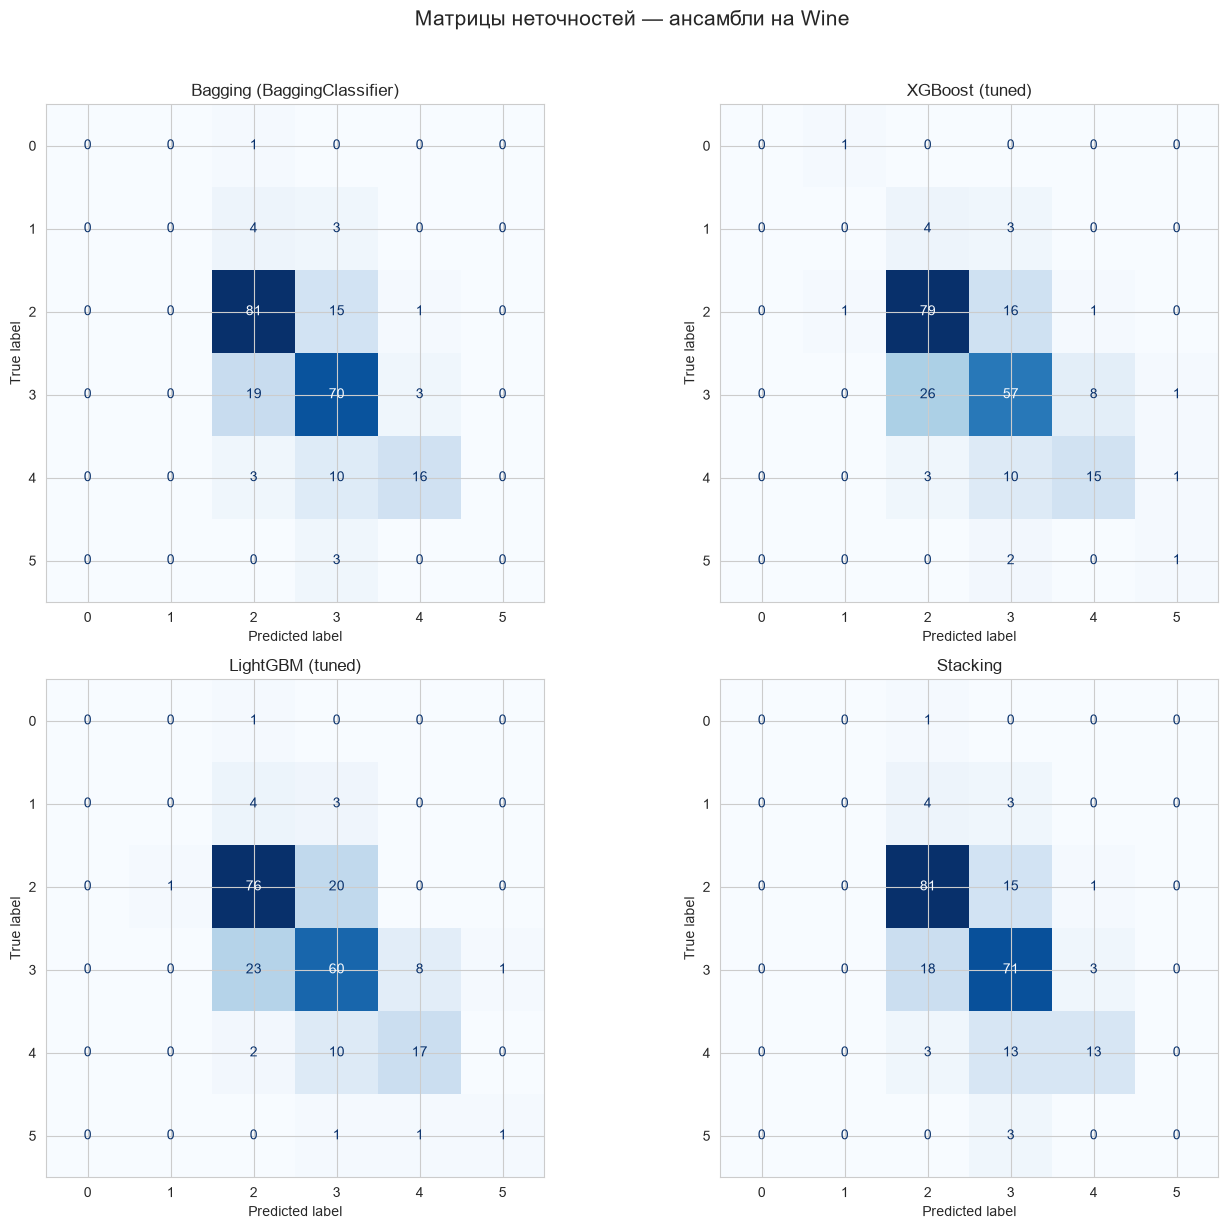

In [23]:
# Confusion Matrix — все ансамбли на Wine
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

all_wine_preds = {
    'Bagging (BaggingClassifier)': y_pred_bag_w,
    'XGBoost (tuned)': y_pred_xgb_tuned_w,
    'LightGBM (tuned)': y_pred_lgb_tuned_w,
    'Stacking': y_pred_stack_w
}

for i, (name, y_pred) in enumerate(all_wine_preds.items()):
    cm = confusion_matrix(y_test_w, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name}', fontsize=12)

plt.suptitle('Матрицы неточностей — ансамбли на Wine', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

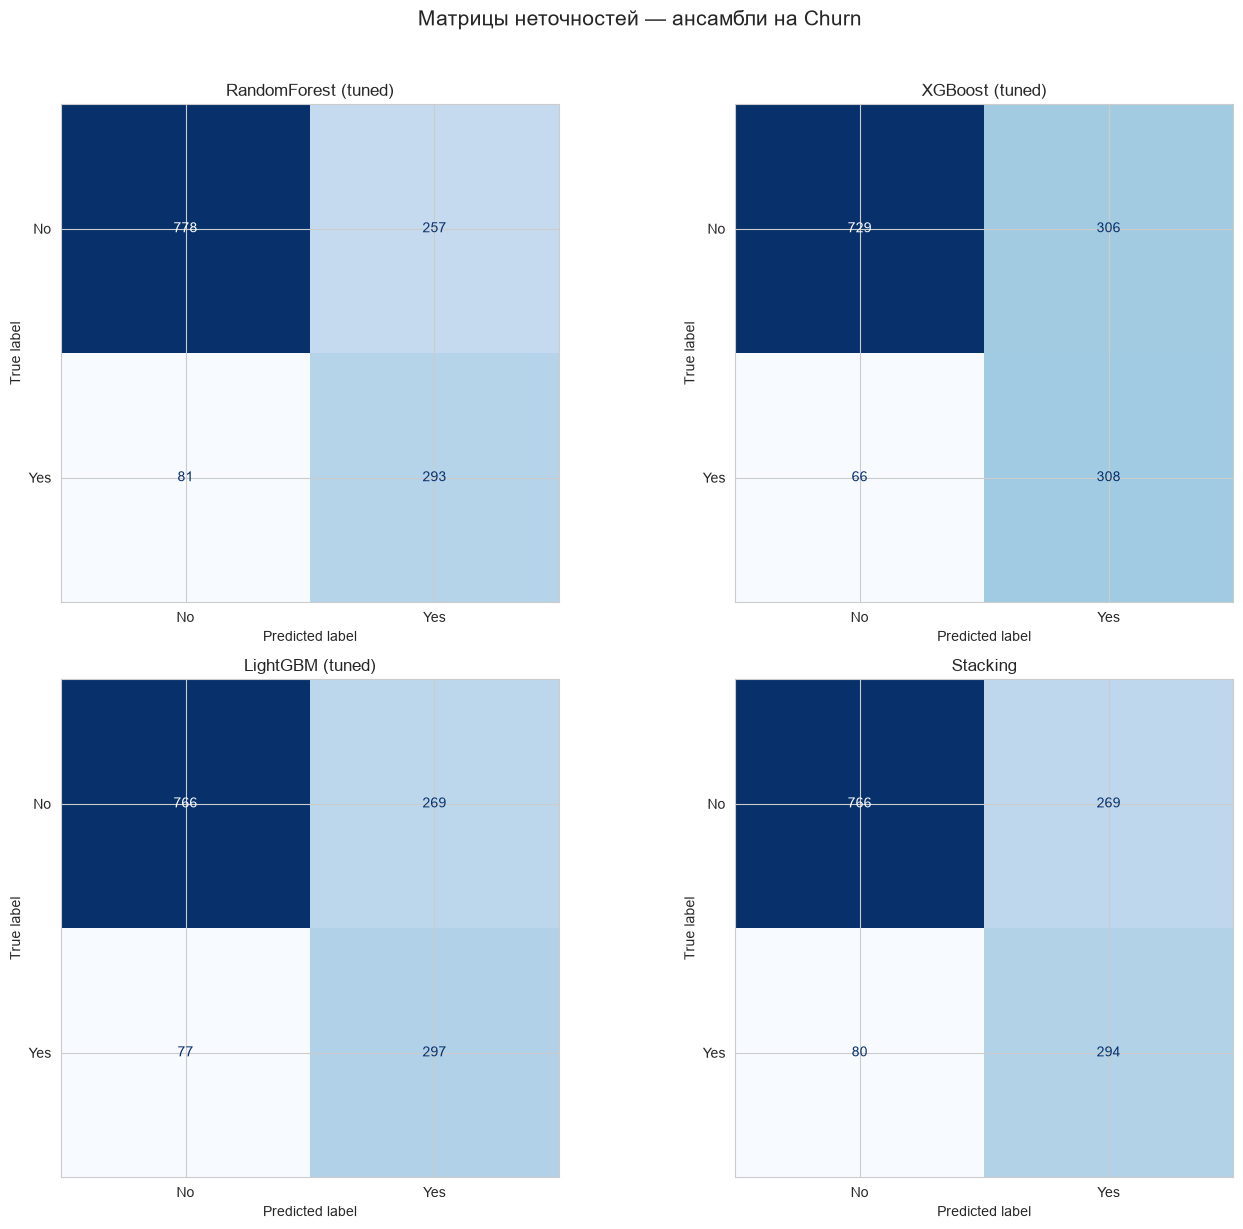

In [24]:
# Confusion Matrix — все ансамбли на Churn
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

all_churn_preds = {
    'RandomForest (tuned)': y_pred_rf_tuned_c,
    'XGBoost (tuned)': y_pred_xgb_tuned_c,
    'LightGBM (tuned)': y_pred_lgb_tuned_c,
    'Stacking': y_pred_stack_c
}

for i, (name, y_pred) in enumerate(all_churn_preds.items()):
    cm = confusion_matrix(y_test_c, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'{name}', fontsize=12)

plt.suptitle('Матрицы неточностей — ансамбли на Churn', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

## Стэкинг (Stacking)

### Архитектура стэкинга в работе

**Level 0 (базовые модели):**
- SVM (RBF-ядро, `probability=True`)
- Decision Tree
- RandomForest

**Level 1 (мета-модель):**
- LogisticRegression

**Ключевой параметр:** `stack_method='predict_proba'` — мета-модель получает **вероятности**, а не классы. Это даёт больше информации для взвешивания.

### Результаты

**Wine:**
| Метрика | Значение |
|---|---|
| Accuracy | 0.7205 |
| F1 (weighted) | 0.6975 |

**Churn:**
| Метрика | Значение |
|---|---|
| Accuracy | 0.7523 |
| Precision | 0.5222 |
| Recall | 0.7861 |
| F1 | 0.6275 |

### Наблюдения

1. **Wine:** стэкинг (F1 0.6975) **проиграл** BaggingClassifier (F1 0.7089), но **обогнал** бустинг. Базовые модели уже сильные и коррелированные, мета-модель не смогла их «усилить» — просто взвесила.

2. **Churn:** стэкинг (F1 0.6275) занял **второе место** после RandomForest tuned (0.6342), почти догнав XGBoost tuned (0.6235). Отличный Recall (0.786) — модель хорошо ловит уходящих.

3. **Стэкинг не «серебряная пуля».** Он раскрывается, когда базовые модели **разнородны** и **сильны в разных аспектах**. Если базовые модели коррелированы (например, несколько деревьев), прирост минимален.

4. **Recall высокий у стэкинга на Churn (0.786)** — это прямое следствие того, что базовые модели обучались с `class_weight='balanced'`. Мета-модель «наследует» эту склонность ловить миноритарный класс.

**Вывод:** стэкинг — мощный инструмент, но **не всегда выигрывает**. На Wine чистый бэггинг (BaggingClassifier) оказался лучше, на Churn — RandomForest tuned. Однако стэкинг даёт **стабильно хороший Recall** на задаче churn, что для бизнеса ценно.

In [25]:
# Глобальная сводка по ЛР4 + ЛР5
print("=" * 80)
print("ГЛОБАЛЬНОЕ СРАВНЕНИЕ: КЛАССИКА (ЛР4) vs АНСАМБЛИ (ЛР5)")
print("=" * 80)

# WINE
print("\nWINE QUALITY (multiclass)")
print("-" * 80)

wine_global = pd.DataFrame([
    {'Group': 'Classic (ЛР4)', 'Model': 'Decision Tree', 'Accuracy': 0.6332, 'F1': 0.6266},
    {'Group': 'Classic (ЛР4)', 'Model': 'SVM', 'Accuracy': 0.6681, 'F1': 0.6420},
    {'Group': 'Classic (ЛР4)', 'Model': 'MLP', 'Accuracy': 0.6376, 'F1': 0.6229},
    {'Group': 'Bagging (ЛР5)', 'Model': 'RandomForest', 'Accuracy': 0.7118, 'F1': 0.6893},
    {'Group': 'Bagging (ЛР5)', 'Model': 'BaggingClassifier', 'Accuracy': 0.7293, 'F1': 0.7089},
    {'Group': 'Boosting (ЛР5)', 'Model': 'XGBoost (tuned)', 'Accuracy': 0.6638, 'F1': 0.6507},
    {'Group': 'Boosting (ЛР5)', 'Model': 'LightGBM (tuned)', 'Accuracy': 0.6725, 'F1': 0.6599},
    {'Group': 'Stacking (ЛР5)', 'Model': 'Stacking (SVM+DT+RF)', 'Accuracy': 0.7205, 'F1': 0.6975},
])
print(wine_global.to_string(index=False))
print()

# CHURN
print("\nTELCO CUSTOMER CHURN (binary)")
print("-" * 80)

churn_global = pd.DataFrame([
    {'Group': 'Classic (ЛР4)', 'Model': 'Decision Tree', 'Accuracy': 0.7410, 'Recall': 0.7941, 'F1': 0.6194},
    {'Group': 'Classic (ЛР4)', 'Model': 'SVM', 'Accuracy': 0.7339, 'Recall': 0.7941, 'F1': 0.6130},
    {'Group': 'Classic (ЛР4)', 'Model': 'kNN', 'Accuracy': 0.7821, 'Recall': 0.5722, 'F1': 0.5823},
    {'Group': 'Classic (ЛР4)', 'Model': 'MLP', 'Accuracy': 0.7885, 'Recall': 0.5080, 'F1': 0.5605},
    {'Group': 'Bagging (ЛР5)', 'Model': 'RandomForest (tuned)', 'Accuracy': 0.7601, 'Recall': 0.7834, 'F1': 0.6342},
    {'Group': 'Boosting (ЛР5)', 'Model': 'XGBoost (tuned)', 'Accuracy': 0.7360, 'Recall': 0.8235, 'F1': 0.6235},
    {'Group': 'Boosting (ЛР5)', 'Model': 'LightGBM (tuned)', 'Accuracy': 0.7544, 'Recall': 0.7941, 'F1': 0.6319},
    {'Group': 'Stacking (ЛР5)', 'Model': 'Stacking (SVM+DT+RF)', 'Accuracy': 0.7523, 'Recall': 0.7861, 'F1': 0.6275},
])
print(churn_global.to_string(index=False))
print()

# ЛУЧШИЕ МОДЕЛИ
print("=" * 80)
print("ЛУЧШИЕ МОДЕЛИ ПО F1")
print("=" * 80)

best_wine = wine_global.loc[wine_global['F1'].idxmax()]
print(f"Wine:   {best_wine['Model']:30} F1 = {best_wine['F1']}")

best_churn = churn_global.loc[churn_global['F1'].idxmax()]
print(f"Churn:  {best_churn['Model']:30} F1 = {best_churn['F1']}")

ГЛОБАЛЬНОЕ СРАВНЕНИЕ: КЛАССИКА (ЛР4) vs АНСАМБЛИ (ЛР5)

WINE QUALITY (multiclass)
--------------------------------------------------------------------------------
         Group                Model  Accuracy     F1
 Classic (ЛР4)        Decision Tree    0.6332 0.6266
 Classic (ЛР4)                  SVM    0.6681 0.6420
 Classic (ЛР4)                  MLP    0.6376 0.6229
 Bagging (ЛР5)         RandomForest    0.7118 0.6893
 Bagging (ЛР5)    BaggingClassifier    0.7293 0.7089
Boosting (ЛР5)      XGBoost (tuned)    0.6638 0.6507
Boosting (ЛР5)     LightGBM (tuned)    0.6725 0.6599
Stacking (ЛР5) Stacking (SVM+DT+RF)    0.7205 0.6975


TELCO CUSTOMER CHURN (binary)
--------------------------------------------------------------------------------
         Group                Model  Accuracy  Recall     F1
 Classic (ЛР4)        Decision Tree    0.7410  0.7941 0.6194
 Classic (ЛР4)                  SVM    0.7339  0.7941 0.6130
 Classic (ЛР4)                  kNN    0.7821  0.5722 0.5823
 Cl